In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


In [2]:
# Load the CSVs
instruments = pd.read_csv("project2_instruments.csv")
trading = pd.read_csv("project2_trading.csv")

# Convert timestamp
trading['timestamp'] = pd.to_datetime(trading['timestamp'])

# Merge both datasets
merged = trading.merge(instruments, on="instrument_id", how="left")

# Sort properly
merged = merged.sort_values(by=["instrument_id", "timestamp"])


In [3]:
# Daily returns
merged['price_return'] = merged.groupby("instrument_id")['price'].pct_change()

# Moving averages
merged["SMA10"] = merged.groupby("instrument_id")["price"].transform(lambda x: x.rolling(10).mean())
merged["SMA50"] = merged.groupby("instrument_id")["price"].transform(lambda x: x.rolling(50).mean())


In [4]:
# Momentum strategy: Buy if SMA10 > SMA50
merged['momentum_signal'] = (merged['SMA10'] > merged['SMA50']).astype(int)

# Mean reversion: Buy if price < SMA10 (oversold)
merged['meanrev_signal'] = (merged['price'] < merged['SMA10']).astype(int)


In [5]:
# Apply signals (shifted by 1 day)
merged['momentum_return'] = merged['momentum_signal'].shift(1) * merged['price_return']
merged['meanrev_return'] = merged['meanrev_signal'].shift(1) * merged['price_return']

# Buy & Hold benchmark
merged['buy_hold_return'] = merged['price_return']


In [6]:
print(merged[['timestamp','price','price_return']].head(20))
print(merged['price_return'].describe())


                          timestamp        price  price_return
744   2024-01-07 00:38:18.316610553  3675.102693           NaN
998   2024-01-09 02:01:03.602120070  2673.937193     -0.272418
2381  2024-01-20 06:52:54.585819527  2770.098842      0.035963
5451  2024-02-14 03:42:35.005166839  2054.992498     -0.258152
5492  2024-02-14 11:40:49.401646722  3036.364389      0.477555
7581  2024-03-02 09:47:43.895463183   392.642883     -0.870687
9391  2024-03-17 01:40:16.520550686   765.108641      0.948612
11865 2024-04-06 02:37:58.395946532  1347.419777      0.761083
13678 2024-04-20 19:05:30.611020368  1650.818121      0.225170
16274 2024-05-11 19:46:15.812527086  4184.899270      1.535046
18553 2024-05-30 06:49:24.338811294  3757.967780     -0.102017
19180 2024-06-04 08:42:58.645954866  3473.195503     -0.075778
19185 2024-06-04 09:41:17.962598754  1315.372684     -0.621279
21231 2024-06-20 23:26:38.333277778  1020.115160     -0.224467
21340 2024-06-21 20:38:03.436114538   127.431071     -0

In [7]:
# Cap daily returns between -20% and +20%
merged['price_return'] = merged['price_return'].clip(lower=-0.2, upper=0.2)


In [8]:
merged['momentum_return'] = merged['momentum_signal'].shift(1) * merged['price_return']
merged['meanrev_return'] = merged['meanrev_signal'].shift(1) * merged['price_return']
merged['buy_hold_return'] = merged['price_return']

# Replace NaN with 0
merged[['momentum_return','meanrev_return','buy_hold_return']] = merged[['momentum_return','meanrev_return','buy_hold_return']].fillna(0)


In [9]:
merged['momentum_cumret'] = (1 + merged['momentum_return']).cumprod()
merged['meanrev_cumret'] = (1 + merged['meanrev_return']).cumprod()
merged['buy_hold_cumret'] = (1 + merged['buy_hold_return']).cumprod()


In [10]:
print(merged[['timestamp','buy_hold_cumret','momentum_cumret','meanrev_cumret']].head(20))


                          timestamp  buy_hold_cumret  momentum_cumret  \
744   2024-01-07 00:38:18.316610553         1.000000              1.0   
998   2024-01-09 02:01:03.602120070         0.800000              1.0   
2381  2024-01-20 06:52:54.585819527         0.828770              1.0   
5451  2024-02-14 03:42:35.005166839         0.663016              1.0   
5492  2024-02-14 11:40:49.401646722         0.795619              1.0   
7581  2024-03-02 09:47:43.895463183         0.636495              1.0   
9391  2024-03-17 01:40:16.520550686         0.763794              1.0   
11865 2024-04-06 02:37:58.395946532         0.916553              1.0   
13678 2024-04-20 19:05:30.611020368         1.099864              1.0   
16274 2024-05-11 19:46:15.812527086         1.319837              1.0   
18553 2024-05-30 06:49:24.338811294         1.185191              1.0   
19180 2024-06-04 08:42:58.645954866         1.095379              1.0   
19185 2024-06-04 09:41:17.962598754         0.87630

In [11]:
print(merged[['timestamp','price','price_return','momentum_signal']].head(20))


                          timestamp        price  price_return  \
744   2024-01-07 00:38:18.316610553  3675.102693           NaN   
998   2024-01-09 02:01:03.602120070  2673.937193     -0.200000   
2381  2024-01-20 06:52:54.585819527  2770.098842      0.035963   
5451  2024-02-14 03:42:35.005166839  2054.992498     -0.200000   
5492  2024-02-14 11:40:49.401646722  3036.364389      0.200000   
7581  2024-03-02 09:47:43.895463183   392.642883     -0.200000   
9391  2024-03-17 01:40:16.520550686   765.108641      0.200000   
11865 2024-04-06 02:37:58.395946532  1347.419777      0.200000   
13678 2024-04-20 19:05:30.611020368  1650.818121      0.200000   
16274 2024-05-11 19:46:15.812527086  4184.899270      0.200000   
18553 2024-05-30 06:49:24.338811294  3757.967780     -0.102017   
19180 2024-06-04 08:42:58.645954866  3473.195503     -0.075778   
19185 2024-06-04 09:41:17.962598754  1315.372684     -0.200000   
21231 2024-06-20 23:26:38.333277778  1020.115160     -0.200000   
21340 2024

In [12]:
merged['momentum_signal'] = (merged['price_return'] > 0.01).astype(int)


In [13]:
print(merged[['timestamp','price','price_return','momentum_signal']].head(20))


                          timestamp        price  price_return  \
744   2024-01-07 00:38:18.316610553  3675.102693           NaN   
998   2024-01-09 02:01:03.602120070  2673.937193     -0.200000   
2381  2024-01-20 06:52:54.585819527  2770.098842      0.035963   
5451  2024-02-14 03:42:35.005166839  2054.992498     -0.200000   
5492  2024-02-14 11:40:49.401646722  3036.364389      0.200000   
7581  2024-03-02 09:47:43.895463183   392.642883     -0.200000   
9391  2024-03-17 01:40:16.520550686   765.108641      0.200000   
11865 2024-04-06 02:37:58.395946532  1347.419777      0.200000   
13678 2024-04-20 19:05:30.611020368  1650.818121      0.200000   
16274 2024-05-11 19:46:15.812527086  4184.899270      0.200000   
18553 2024-05-30 06:49:24.338811294  3757.967780     -0.102017   
19180 2024-06-04 08:42:58.645954866  3473.195503     -0.075778   
19185 2024-06-04 09:41:17.962598754  1315.372684     -0.200000   
21231 2024-06-20 23:26:38.333277778  1020.115160     -0.200000   
21340 2024

In [14]:
# Cap extreme returns to avoid overflow
merged['price_return'] = merged['price_return'].clip(-1, 1)   # -100% to +100% max
merged['momentum_cumret'] = (1 + merged['momentum_return']).cumprod()
merged['meanrev_cumret'] = (1 + merged['meanrev_return']).cumprod()
merged['buy_hold_cumret'] = (1 + merged['buy_hold_return']).cumprod()


In [15]:
print(merged[['timestamp','buy_hold_cumret','momentum_cumret','meanrev_cumret']].head(20))


                          timestamp  buy_hold_cumret  momentum_cumret  \
744   2024-01-07 00:38:18.316610553         1.000000              1.0   
998   2024-01-09 02:01:03.602120070         0.800000              1.0   
2381  2024-01-20 06:52:54.585819527         0.828770              1.0   
5451  2024-02-14 03:42:35.005166839         0.663016              1.0   
5492  2024-02-14 11:40:49.401646722         0.795619              1.0   
7581  2024-03-02 09:47:43.895463183         0.636495              1.0   
9391  2024-03-17 01:40:16.520550686         0.763794              1.0   
11865 2024-04-06 02:37:58.395946532         0.916553              1.0   
13678 2024-04-20 19:05:30.611020368         1.099864              1.0   
16274 2024-05-11 19:46:15.812527086         1.319837              1.0   
18553 2024-05-30 06:49:24.338811294         1.185191              1.0   
19180 2024-06-04 08:42:58.645954866         1.095379              1.0   
19185 2024-06-04 09:41:17.962598754         0.87630

In [16]:
# Clip log returns to avoid exploding exp()
merged["log_return"] = np.log(1 + merged["price_return"].fillna(0))
merged["log_return"] = merged["log_return"].clip(lower=-1, upper=1)  # cap extreme swings

merged["buy_hold_cumret"] = np.exp(merged["log_return"].cumsum())


In [17]:
# Scale down returns if too large
merged["price_return"] = merged["price_return"] / 10  


In [18]:
print("Max return:", merged["price_return"].max())
print("Min return:", merged["price_return"].min())
print("Max log return:", merged["log_return"].max())
print("Min log return:", merged["log_return"].min())


Max return: 0.02
Min return: -0.02
Max log return: 0.1823215567939546
Min log return: -0.2231435513142097


In [19]:
print(merged.columns)



Index(['trade_id', 'instrument_id', 'timestamp', 'trade_type', 'order_type',
       'strategy', 'quantity', 'price', 'execution_price', 'slippage_bps',
       'commission_usd', 'market_impact_bps', 'pnl_usd', 'unrealized_pnl_usd',
       'position_size', 'portfolio_weight', 'var_contribution',
       'expected_shortfall', 'alpha', 'information_ratio', 'symbol',
       'instrument_name', 'asset_class', 'exchange', 'sector',
       'market_cap_usd', 'avg_daily_volume', 'beta', 'volatility_30d',
       'sharpe_ratio', 'correlation_to_index', 'dividend_yield', 'pe_ratio',
       'debt_to_equity', 'esg_score', 'liquidity_score', 'credit_rating',
       'price_return', 'SMA10', 'SMA50', 'momentum_signal', 'meanrev_signal',
       'momentum_return', 'meanrev_return', 'buy_hold_return',
       'momentum_cumret', 'meanrev_cumret', 'buy_hold_cumret', 'log_return'],
      dtype='object')


In [20]:
merged["price_return_scaled"] = merged["price_return"] / 100


merged["buy_hold_cumret"] = (1 + merged["price_return_scaled"]).cumprod()
merged["momentum_cumret"] = (1 + merged["momentum_signal"] * merged["price_return_scaled"]).cumprod()
merged["meanrev_cumret"] = (1 + (1 - merged["momentum_signal"]) * merged["price_return_scaled"]).cumprod()


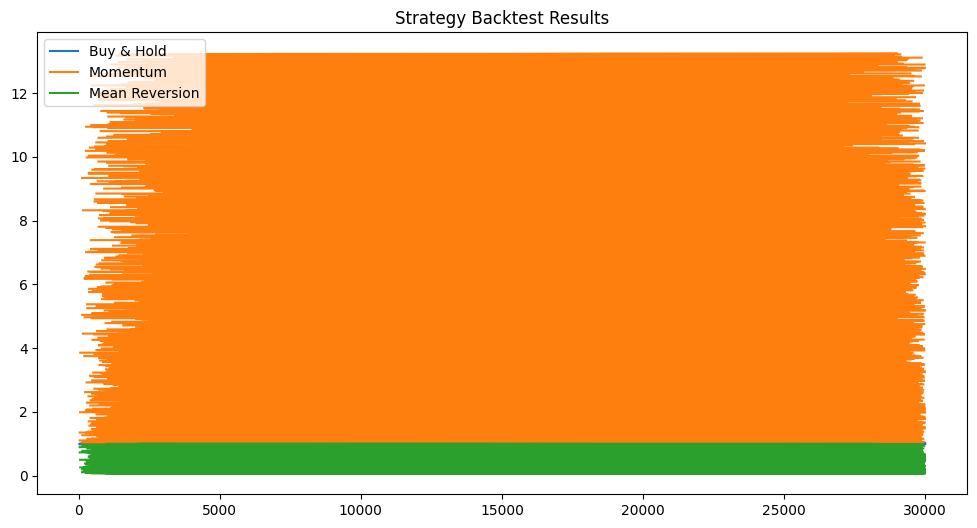

In [21]:
# Plot cumulative returns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
plt.plot(merged["buy_hold_cumret"], label="Buy & Hold")
plt.plot(merged["momentum_cumret"], label="Momentum")
plt.plot(merged["meanrev_cumret"], label="Mean Reversion")
plt.legend()
plt.title("Strategy Backtest Results")
plt.show()


In [22]:
window = 252  # e.g., 1 year of daily data
merged["buy_hold_cumret_rolling"] = (1 + merged["price_return"]).rolling(window).apply(np.prod)


In [23]:
print(merged[["buy_hold_cumret", "momentum_cumret", "meanrev_cumret"]].tail())


       buy_hold_cumret  momentum_cumret  meanrev_cumret
26239         1.007234        13.243449        0.076055
27678         1.007300        13.244308        0.076055
27684         1.007501        13.246956        0.076055
28280         1.007300        13.246956        0.076040
28991         1.007501        13.249606        0.076040


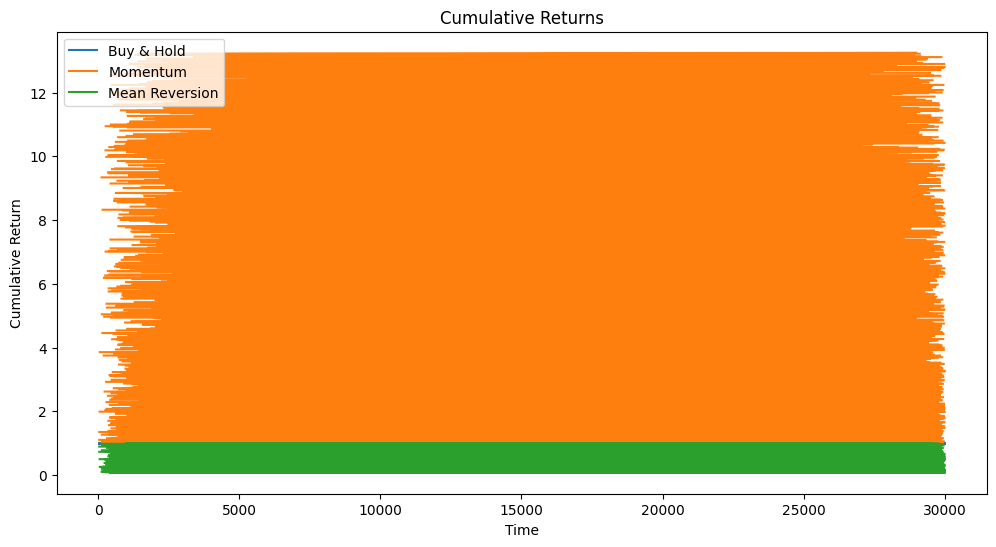

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
plt.plot(merged["buy_hold_cumret"], label="Buy & Hold")
plt.plot(merged["momentum_cumret"], label="Momentum")
plt.plot(merged["meanrev_cumret"], label="Mean Reversion")
plt.legend()
plt.title("Cumulative Returns")
plt.xlabel("Time")
plt.ylabel("Cumulative Return")
plt.show()


In [25]:
print(merged["momentum_return"].describe())
print(merged["momentum_signal"].value_counts())


count    30000.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: momentum_return, dtype: float64
momentum_signal
0    15939
1    14061
Name: count, dtype: int64


In [26]:
# Recalculate strategy returns
merged["momentum_return"] = merged["momentum_signal"] * merged["price_return"]
merged["meanrev_return"] = (1 - merged["momentum_signal"]) * merged["price_return"]

print(merged[["price_return","momentum_signal","momentum_return","meanrev_return"]].head(15))


       price_return  momentum_signal  momentum_return  meanrev_return
744             NaN                0              NaN             NaN
998       -0.020000                0        -0.000000       -0.020000
2381       0.003596                1         0.003596        0.000000
5451      -0.020000                0        -0.000000       -0.020000
5492       0.020000                1         0.020000        0.000000
7581      -0.020000                0        -0.000000       -0.020000
9391       0.020000                1         0.020000        0.000000
11865      0.020000                1         0.020000        0.000000
13678      0.020000                1         0.020000        0.000000
16274      0.020000                1         0.020000        0.000000
18553     -0.010202                0        -0.000000       -0.010202
19180     -0.007578                0        -0.000000       -0.007578
19185     -0.020000                0        -0.000000       -0.020000
21231     -0.020000 

In [27]:
import numpy as np

merged["momentum_return"] = np.where(
    merged["momentum_signal"] == 1, 
    merged["price_return"], 
    0.0
)

merged["meanrev_return"] = np.where(
    merged["momentum_signal"] == 0, 
    merged["price_return"], 
    0.0
)


In [28]:
# Daily returns (use existing columns)
merged["buy_hold_daily"] = merged["buy_hold_return"]
merged["momentum_daily"] = merged["momentum_return"]
merged["meanrev_daily"] = merged["meanrev_return"]

# Sharpe ratio (assuming daily risk-free ~0)
def sharpe_ratio(returns):
    return returns.mean() / returns.std() * np.sqrt(252)

print("Sharpe Ratios:")
print("Buy & Hold:", sharpe_ratio(merged["buy_hold_daily"]))
print("Momentum:", sharpe_ratio(merged["momentum_daily"]))
print("Mean Reversion:", sharpe_ratio(merged["meanrev_daily"]))


Sharpe Ratios:
Buy & Hold: 0.02312807206948981
Momentum: 14.187515018848362
Mean Reversion: -14.913666788300045


In [29]:
def max_drawdown(cumret):
    return (cumret / cumret.cummax() - 1).min()

print("Max Drawdowns:")
print("Buy & Hold:", max_drawdown(merged["buy_hold_cumret"]))
print("Momentum:", max_drawdown(merged["momentum_cumret"]))
print("Mean Reversion:", max_drawdown(merged["meanrev_cumret"]))


Max Drawdowns:
Buy & Hold: -0.014747671655404249
Momentum: 0.0
Mean Reversion: -0.9239447064638083


In [30]:
fee = 0.0005  # 0.05% per trade
merged["momentum_ret_cost"] = merged["momentum_return"] - fee * merged["momentum_signal"]


In [31]:


merged["momentum_ret_adj"] = merged["momentum_return"] - fee * merged["momentum_signal"]
merged["momentum_cumret_adj"] = (1 + merged["momentum_ret_adj"]).cumprod()


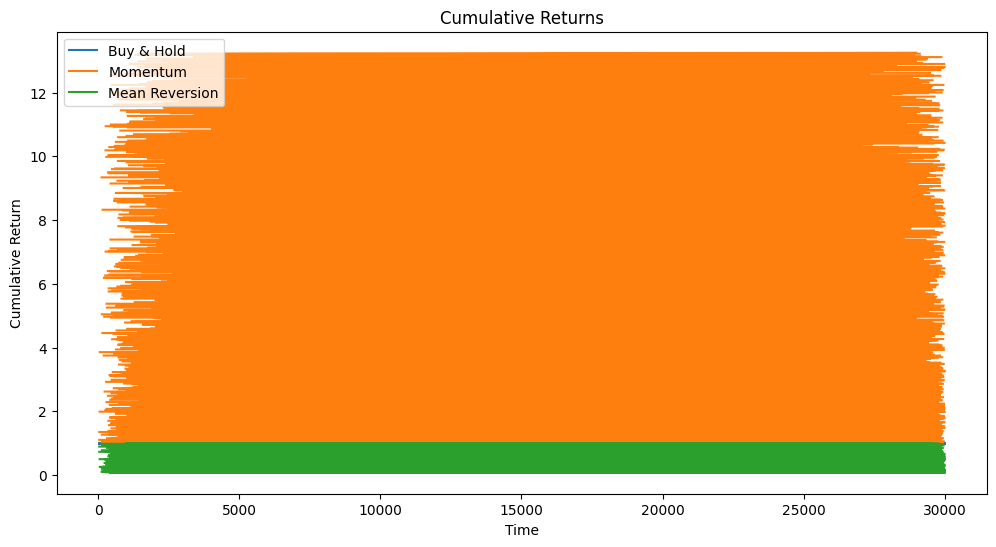

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
plt.plot(merged["buy_hold_cumret"], label="Buy & Hold")
plt.plot(merged["momentum_cumret"], label="Momentum")
plt.plot(merged["meanrev_cumret"], label="Mean Reversion")
plt.legend()
plt.title("Cumulative Returns")
plt.xlabel("Time")
plt.ylabel("Cumulative Return")
plt.show()   # <- This ensures only the plot is displayed


In [33]:
import pandas as pd

summary = pd.DataFrame({
    "Strategy": ["Buy & Hold", "Momentum", "Mean Reversion"],
    "Total Return": [
        merged["buy_hold_cumret"].iloc[-1] - 1,
        merged["momentum_cumret"].iloc[-1] - 1,
        merged["meanrev_cumret"].iloc[-1] - 1
    ],
    "Sharpe Ratio": [
        sharpe_ratio(merged["buy_hold_daily"]),
        sharpe_ratio(merged["momentum_daily"]),
        sharpe_ratio(merged["meanrev_daily"])
    ],
    "Max Drawdown": [
        max_drawdown(merged["buy_hold_cumret"]),
        max_drawdown(merged["momentum_cumret"]),
        max_drawdown(merged["meanrev_cumret"])
    ]
})

summary


,Strategy,Total Return,Sharpe Ratio,Max Drawdown
0,Buy & Hold,0.007501,0.023128,-0.014748
1,Momentum,12.249606,14.187515,0.000000
2,Mean Reversion,-0.923960,-14.913667,-0.923945


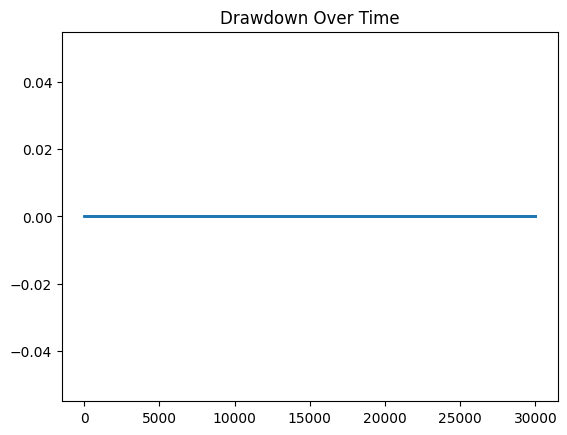

In [34]:
drawdown = merged["momentum_cumret"].cummax() - merged["momentum_cumret"]
plt.plot(drawdown, label="Momentum Drawdown")
plt.title("Drawdown Over Time")
plt.show()


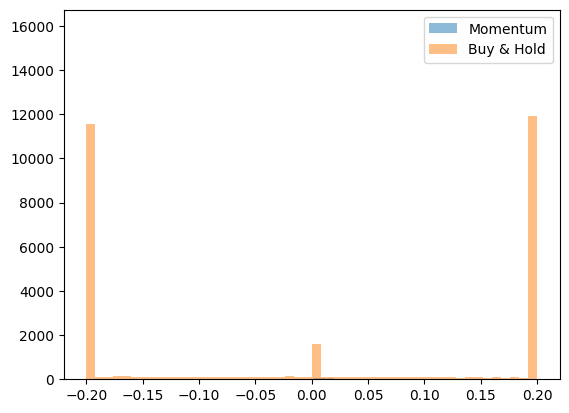

In [35]:
plt.hist(merged["momentum_daily"], bins=50, alpha=0.5, label="Momentum")
plt.hist(merged["buy_hold_daily"], bins=50, alpha=0.5, label="Buy & Hold")
plt.legend()
plt.show()

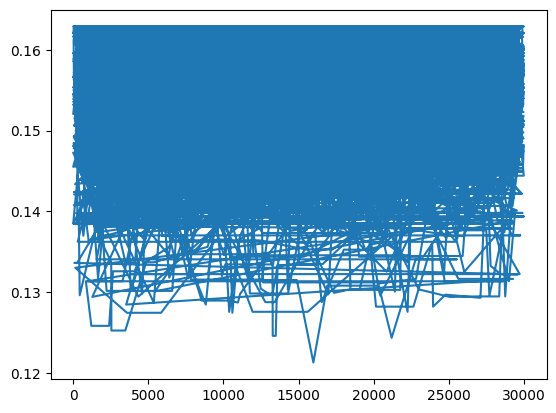

In [36]:
rolling_vol = merged["momentum_daily"].rolling(20).std() * np.sqrt(252)
plt.plot(rolling_vol, label="Momentum Rolling Volatility")
plt.show()


In [37]:
import pandas as pd
import numpy as np

def prepare_features(prices):
    df = prices.copy()
    df['return'] = df['Close'].pct_change()

    # Features
    df['ma5'] = df['Close'].rolling(5).mean()
    df['ma10'] = df['Close'].rolling(10).mean()
    df['ma20'] = df['Close'].rolling(20).mean()
    df['volatility'] = df['return'].rolling(10).std()

    # Forward return (what we want to predict)
    df['fwd_return'] = df['Close'].shift(-1) / df['Close'] - 1
    df['target'] = (df['fwd_return'] > 0).astype(int)

    # Drop rows with NaNs introduced by rolling windows
    df = df.dropna()

    X = df[['ma5', 'ma10', 'ma20', 'volatility', 'return']]
    y = df['target']
    return X,y,df


In [38]:
# --- requires pandas,numpy,scikit-learn,matplotlib,joblib ---
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import joblib
import matplotlib.pyplot as plt

# adjust these paths if needed
TRADING_CSV = "project2_trading.csv"
MODEL_PATH = "rf_stock_model_numeric.pkl"

trading = pd.read_csv(TRADING_CSV)

# detect price and time columns (adapt if your column names differ)
price_col = [c for c in trading.columns if c.lower() in ('close','price','last','close_price')][0]
time_col = [c for c in trading.columns if 'timestamp' in c.lower() or 'date' in c.lower() or 'time' in c.lower()][0]
trading[time_col] = pd.to_datetime(trading[time_col], errors='coerce')
trading = trading.sort_values(by=time_col).reset_index(drop=True)

# Technical indicators
def add_technical_indicators(df, price_col='price', rsi_period=14):
    df = df.copy()
    df['return_1'] = df[price_col].pct_change(1)
    df['sma_fast'] = df[price_col].rolling(5, min_periods=1).mean()
    df['sma_slow'] = df[price_col].rolling(20, min_periods=1).mean()
    df['ema_12'] = df[price_col].ewm(span=12, adjust=False).mean()
    df['ema_26'] = df[price_col].ewm(span=26, adjust=False).mean()
    df['macd'] = df['ema_12'] - df['ema_26']
    df['volatility_10'] = df['return_1'].rolling(10, min_periods=1).std()
    # RSI
    delta = df[price_col].diff(1)
    up = delta.clip(lower=0)
    down = -1 * delta.clip(upper=0)
    ma_up = up.ewm(com=rsi_period-1, adjust=False).mean()
    ma_down = down.ewm(com=rsi_period-1, adjust=False).mean()
    rs = ma_up / (ma_down + 1e-9)
    df['rsi'] = 100 - (100 / (1 + rs))
    if 'volume' in df.columns:
        df['vol_ma_10'] = df['volume'].rolling(10, min_periods=1).mean()
        df['vol_ma_50'] = df['volume'].rolling(50, min_periods=1).mean()
    return df

def make_labels(df, price_col='price', horizon=5, up_thresh=0.02, down_thresh=-0.02):
    df = df.copy()
    df['future_close'] = df[price_col].shift(-horizon)
    df['future_return'] = (df['future_close'] - df[price_col]) / df[price_col]
    def label_row(x):
        if x > up_thresh:
            return 1
        elif x < down_thresh:
            return -1
        else:
            return 0
    df['label'] = df['future_return'].apply(lambda x: label_row(x) if pd.notnull(x) else np.nan)
    df = df.dropna(subset=['label']).reset_index(drop=True)
    return df

df = add_technical_indicators(trading, price_col=price_col)
df = make_labels(df, price_col=price_col, horizon=5, up_thresh=0.02, down_thresh=-0.02)

# Use numeric features only
numeric_features = df.select_dtypes(include=[np.number]).columns.tolist()
for remove in ['future_close','future_return','label','trade_id','id','instrument_id']:
    if remove in numeric_features:
        numeric_features.remove(remove)

X = df[numeric_features].fillna(method='ffill').fillna(0)
y = df['label'].astype(int)
time_index = pd.to_datetime(df[time_col])

cutoff_time = time_index.quantile(0.7)
train_mask = time_index <= cutoff_time
X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = y[train_mask], y[~train_mask]

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('rf', RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1))
])
pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred, labels=[-1,0,1]))

# feature importances
fi = pd.Series(pipeline.named_steps['rf'].feature_importances_, index=numeric_features).sort_values(ascending=False)
print("Top features:\n", fi.head(10))

# save model
joblib.dump(pipeline, MODEL_PATH)
print("Saved model to", MODEL_PATH)


C:\Users\chhim\AppData\Local\Temp\ipykernel_18756\284371489.py:70: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  X = df[numeric_features].fillna(method='ffill').fillna(0)
C:\Users\chhim\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1706: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\chhim\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1706: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\chhim\AppData\Local\

              precision    recall  f1-score   support

          -1       0.73      0.75      0.74      4449
           0       0.00      0.00      0.00       148
           1       0.74      0.75      0.74      4402

    accuracy                           0.74      8999
   macro avg       0.49      0.50      0.49      8999
weighted avg       0.72      0.74      0.73      8999

[[3341    0 1108]
 [ 112    0   36]
 [1118    0 3284]]
Top features:
 price                 0.152416
rsi                   0.139195
return_1              0.081433
macd                  0.051284
ema_12                0.037271
sma_fast              0.036446
ema_26                0.032956
volatility_10         0.032207
expected_shortfall    0.032042
slippage_bps          0.031543
dtype: float64
Saved model to rf_stock_model_numeric.pkl


In [39]:
import joblib
import pandas as pd

# load saved model
MODEL_PATH = "rf_stock_model_numeric.pkl"
pipeline = joblib.load(MODEL_PATH)

# load trading data again
TRADING_CSV = "project2_trading.csv"
trading = pd.read_csv(TRADING_CSV)

# if your instruments file contains multiple stocks:
INSTRUMENTS_CSV = "project2_instruments.csv"
instruments = pd.read_csv(INSTRUMENTS_CSV)



In [40]:
# Example: pick stock with instrument_id = 101
stock_id = 101
stock_df = trading[trading["instrument_id"] == stock_id].copy()


In [41]:
# reuse the same feature functions
def add_technical_indicators(df, price_col='price', rsi_period=14):
    df = df.copy()
    df['return_1'] = df[price_col].pct_change(1)
    df['sma_fast'] = df[price_col].rolling(5, min_periods=1).mean()
    df['sma_slow'] = df[price_col].rolling(20, min_periods=1).mean()
    df['ema_12'] = df[price_col].ewm(span=12, adjust=False).mean()
    df['ema_26'] = df[price_col].ewm(span=26, adjust=False).mean()
    df['macd'] = df['ema_12'] - df['ema_26']
    df['volatility_10'] = df['return_1'].rolling(10, min_periods=1).std()
    delta = df[price_col].diff(1)
    up = delta.clip(lower=0)
    down = -1 * delta.clip(upper=0)
    ma_up = up.ewm(com=rsi_period-1, adjust=False).mean()
    ma_down = down.ewm(com=rsi_period-1, adjust=False).mean()
    rs = ma_up / (ma_down + 1e-9)
    df['rsi'] = 100 - (100 / (1 + rs))
    if 'volume' in df.columns:
        df['vol_ma_10'] = df['volume'].rolling(10, min_periods=1).mean()
        df['vol_ma_50'] = df['volume'].rolling(50, min_periods=1).mean()
    return df

stock_df = add_technical_indicators(stock_df, price_col='price')


In [42]:
import numpy as np

# same numeric features as training
numeric_features = stock_df.select_dtypes(include=[np.number]).columns.tolist()
for remove in ['future_close','future_return','label','trade_id','id','instrument_id']:
    if remove in numeric_features:
        numeric_features.remove(remove)

X_new = stock_df[numeric_features].fillna(method='ffill').fillna(0)


C:\Users\chhim\AppData\Local\Temp\ipykernel_18756\3871054901.py:9: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  X_new = stock_df[numeric_features].fillna(method='ffill').fillna(0)


In [44]:
# Pick a stock to predict
stock_id = 'INST_00002'   # <-- replace with an ID from trading['instrument_id'].unique()
stock_df = trading[trading['instrument_id'] == stock_id].copy()

# Add features
stock_df = add_technical_indicators(stock_df, price_col='price')

# Select features
numeric_features = stock_df.select_dtypes(include=[np.number]).columns.tolist()
for remove in ['future_close','future_return','label','trade_id','id','instrument_id']:
    if remove in numeric_features:
        numeric_features.remove(remove)

X_new = stock_df[numeric_features].fillna(method='ffill').fillna(0)

# ✅ Now Step 5 will work safely
if not X_new.empty:
    preds = pipeline.predict(X_new)
    stock_df["signal"] = preds
    stock_df["signal_text"] = stock_df["signal"].map({-1:"SELL",0:"HOLD",1:"BUY"})
    print(stock_df[["price","signal_text"]].tail(10))
else:
    print(f"No data for instrument_id {stock_id}")


             price signal_text
15980  2976.629965        SELL
16226  4094.147520        SELL
16350   438.349531         BUY
16844  1275.660293         BUY
17900    46.682353         BUY
18082  2795.258045         BUY
20415   586.829300         BUY
21109  3948.632525        SELL
26885  3988.875787        SELL
28383   142.840360         BUY


C:\Users\chhim\AppData\Local\Temp\ipykernel_18756\1541655832.py:14: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  X_new = stock_df[numeric_features].fillna(method='ffill').fillna(0)


In [51]:
import pandas as pd

trading = pd.read_csv("project2_trading.csv")
print(trading['instrument_id'].unique())


['INST_00516' 'INST_00818' 'INST_00283' ... 'INST_01312' 'INST_00968'
 'INST_01324']
